## Datasets

In [2]:
# ============================================================
# MERT FEATURES -> GCD SPLIT
# REAL + AUGMENTED FEATURES
# ============================================================

import os
import random
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 49

random.seed(SEED)
np.random.seed(SEED)


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

REAL_CSV_PATH = "/content/mert_layer6_features.csv"

AUGMENTED_CSV_PATH = (
    "/content/mert_layer6_augmented_features.csv"
)


# ------------------------------------------------------------
# GCD class definitions
# ------------------------------------------------------------

KNOWN_CLASSES = [
    "Accordion",
    "Acoustic_Guitar",
    "Banjo",
    "Electro_Guitar",
    "flute",
    "Harmonium",
    "Trombone",
    "Shakers",
    "Keyboard"
]

UNKNOWN_CLASSES = [
    "Bass_Guitar",
    "Organ",
    "Horn",
    "Mandolin",
    "Drum_set"

]


# ------------------------------------------------------------
# IMPORTANT:
# One fixed class order for the entire experiment.
#
# IDs 0-9  = known classes
# IDs 10-13 = novel classes
# ------------------------------------------------------------

CLASS_ORDER = KNOWN_CLASSES + UNKNOWN_CLASSES

N_KNOWN_CLASSES = len(KNOWN_CLASSES)
N_UNKNOWN_CLASSES = len(UNKNOWN_CLASSES)
N_TOTAL_CLASSES = len(CLASS_ORDER)

N_SAMPLES_PER_CLASS = 1000
N_KNOWN_TRAIN_PER_CLASS = 700

EXPECTED_TOTAL_SAMPLES = 14000
EXPECTED_KNOWN_SAMPLES = 6300
EXPECTED_UNLABELED_SAMPLES = 7700


assert N_KNOWN_CLASSES == 9
assert N_UNKNOWN_CLASSES == 5
assert N_TOTAL_CLASSES == 14


print("=" * 70)
print("CONFIGURATION")
print("=" * 70)

print("Known classes   :", KNOWN_CLASSES)
print("Unknown classes :", UNKNOWN_CLASSES)

print("Total classes   :", N_TOTAL_CLASSES)
print("Samples/class   :", N_SAMPLES_PER_CLASS)
print("Known/class     :", N_KNOWN_TRAIN_PER_CLASS)

print("Seed            :", SEED)

CONFIGURATION
Known classes   : ['Accordion', 'Acoustic_Guitar', 'Banjo', 'Electro_Guitar', 'flute', 'Harmonium', 'Trombone', 'Shakers', 'Keyboard']
Unknown classes : ['Bass_Guitar', 'Organ', 'Horn', 'Mandolin', 'Drum_set']
Total classes   : 14
Samples/class   : 1000
Known/class     : 700
Seed            : 49


In [3]:
# ============================================================
# LOAD ORIGINAL AND AUGMENTED MERT FEATURES
# ============================================================

print("Loading original MERT feature CSV...")
df_real = pd.read_csv(REAL_CSV_PATH)

print("Loading augmented MERT feature CSV...")
df_aug = pd.read_csv(AUGMENTED_CSV_PATH)


print("\nDataset shapes")
print("-" * 60)

print("Real features      :", df_real.shape)
print("Augmented features :", df_aug.shape)

Loading original MERT feature CSV...
Loading augmented MERT feature CSV...

Dataset shapes
------------------------------------------------------------
Real features      : (14000, 771)
Augmented features : (14000, 772)


In [4]:
# ============================================================
# IDENTIFY MERT FEATURE COLUMNS
# ============================================================

FEATURE_COLUMNS_REAL = [
    col
    for col in df_real.columns
    if col.startswith("mert_")
    and col != "mert_layer"
]

FEATURE_COLUMNS_AUG = [
    col
    for col in df_aug.columns
    if col.startswith("mert_")
    and col != "mert_layer"
]


print("Real MERT features      :", len(FEATURE_COLUMNS_REAL))
print("Augmented MERT features :", len(FEATURE_COLUMNS_AUG))


assert len(FEATURE_COLUMNS_REAL) == 768
assert len(FEATURE_COLUMNS_AUG) == 768

assert FEATURE_COLUMNS_REAL == FEATURE_COLUMNS_AUG, (
    "Real and augmented MERT feature columns do not match."
)

FEATURE_COLUMNS = FEATURE_COLUMNS_REAL

print("\nMERT feature columns verified.")

Real MERT features      : 768
Augmented MERT features : 768

MERT feature columns verified.


In [5]:
# ============================================================
# VERIFY REAL <-> AUGMENTED CORRESPONDENCE
# ============================================================

print("\nVerifying real <-> augmented correspondence...")
print("-" * 60)


assert len(df_real) == EXPECTED_TOTAL_SAMPLES, (
    f"Expected {EXPECTED_TOTAL_SAMPLES} real samples, "
    f"found {len(df_real)}"
)

assert len(df_aug) == EXPECTED_TOTAL_SAMPLES, (
    f"Expected {EXPECTED_TOTAL_SAMPLES} augmented samples, "
    f"found {len(df_aug)}"
)


assert (
    df_real["filepath"].astype(str).tolist()
    ==
    df_aug["filepath"].astype(str).tolist()
), (
    "Real and augmented filepath ordering does not match."
)


assert (
    df_real["label"].astype(str).tolist()
    ==
    df_aug["label"].astype(str).tolist()
), (
    "Real and augmented labels do not match row-by-row."
)


print("✓ Same 14,000 samples")
print("✓ Same filepath ordering")
print("✓ Same labels")
print("✓ Real and augmented datasets are aligned")


Verifying real <-> augmented correspondence...
------------------------------------------------------------
✓ Same 14,000 samples
✓ Same filepath ordering
✓ Same labels
✓ Real and augmented datasets are aligned


In [6]:
# ============================================================
# VERIFY DATASET
# ============================================================

print("\nOriginal dataset verification")
print("-" * 60)

print("Number of datapoints :", len(df_real))
print("Number of classes    :", df_real["label"].nunique())
print("Number of features   :", len(FEATURE_COLUMNS))


class_counts = (
    df_real["label"]
    .value_counts()
)


assert len(df_real) == EXPECTED_TOTAL_SAMPLES

assert df_real["label"].nunique() == N_TOTAL_CLASSES

assert len(FEATURE_COLUMNS) == 768


for class_name in CLASS_ORDER:

    assert class_name in class_counts, (
        f"Missing class: {class_name}"
    )

    assert class_counts[class_name] == N_SAMPLES_PER_CLASS, (
        f"{class_name} does not contain "
        f"{N_SAMPLES_PER_CLASS} samples."
    )


print("\nClass counts:")
print(
    df_real["label"]
    .value_counts()
    .reindex(CLASS_ORDER)
)

print("\nDataset verification passed.")


Original dataset verification
------------------------------------------------------------
Number of datapoints : 14000
Number of classes    : 14
Number of features   : 768

Class counts:
label
Accordion          1000
Acoustic_Guitar    1000
Banjo              1000
Electro_Guitar     1000
flute              1000
Harmonium          1000
Trombone           1000
Shakers            1000
Keyboard           1000
Bass_Guitar        1000
Organ              1000
Horn               1000
Mandolin           1000
Drum_set           1000
Name: count, dtype: int64

Dataset verification passed.


In [7]:
# ============================================================
# VERIFY KNOWN / UNKNOWN CLASSES
# ============================================================

dataset_classes = sorted(
    df_real["label"].astype(str).unique()
)

assert set(dataset_classes) == set(CLASS_ORDER)


invalid_known = [
    c for c in KNOWN_CLASSES
    if c not in dataset_classes
]

invalid_unknown = [
    c for c in UNKNOWN_CLASSES
    if c not in dataset_classes
]

assert len(invalid_known) == 0, (
    f"Invalid known classes: {invalid_known}"
)

assert len(invalid_unknown) == 0, (
    f"Invalid unknown classes: {invalid_unknown}"
)


assert set(KNOWN_CLASSES).isdisjoint(
    set(UNKNOWN_CLASSES)
)


print("=" * 70)
print("CLASS DEFINITIONS")
print("=" * 70)

for i, class_name in enumerate(CLASS_ORDER):

    group = (
        "KNOWN"
        if class_name in KNOWN_CLASSES
        else "NOVEL"
    )

    print(
        f"{i:2d}  {class_name:20s}  {group}"
    )

CLASS DEFINITIONS
 0  Accordion             KNOWN
 1  Acoustic_Guitar       KNOWN
 2  Banjo                 KNOWN
 3  Electro_Guitar        KNOWN
 4  flute                 KNOWN
 5  Harmonium             KNOWN
 6  Trombone              KNOWN
 7  Shakers               KNOWN
 8  Keyboard              KNOWN
 9  Bass_Guitar           NOVEL
10  Organ                 NOVEL
11  Horn                  NOVEL
12  Mandolin              NOVEL
13  Drum_set              NOVEL


In [8]:
# ============================================================
# CREATE ONE MASTER GCD SPLIT
#
# 10 known classes:
#   700 labeled
#   300 unlabeled
#
# 4 novel classes:
#   1000 unlabeled
#
# Total:
#   7000 labeled known
#   7000 unlabeled
# ============================================================

rng = np.random.default_rng(SEED)

known_indices = []
unknown_indices = []


for class_name in CLASS_ORDER:

    class_indices = df_real.index[
        df_real["label"].astype(str) == class_name
    ].to_numpy()


    assert len(class_indices) == N_SAMPLES_PER_CLASS


    shuffled_indices = rng.permutation(
        class_indices
    )


    if class_name in KNOWN_CLASSES:

        labeled_indices = shuffled_indices[
            :N_KNOWN_TRAIN_PER_CLASS
        ]

        unlabeled_indices = shuffled_indices[
            N_KNOWN_TRAIN_PER_CLASS:
        ]

        known_indices.extend(
            labeled_indices
        )

        unknown_indices.extend(
            unlabeled_indices
        )

    else:

        # Entire novel class is unlabeled
        unknown_indices.extend(
            shuffled_indices
        )


known_indices = np.array(
    known_indices,
    dtype=np.int64
)

unknown_indices = np.array(
    unknown_indices,
    dtype=np.int64
)


# ------------------------------------------------------------
# Verify the split
# ------------------------------------------------------------

assert len(known_indices) == EXPECTED_KNOWN_SAMPLES
assert len(unknown_indices) == EXPECTED_UNLABELED_SAMPLES

assert len(
    np.intersect1d(
        known_indices,
        unknown_indices
    )
) == 0

assert len(
    np.union1d(
        known_indices,
        unknown_indices
    )
) == EXPECTED_TOTAL_SAMPLES


print("=" * 70)
print("MASTER GCD SPLIT")
print("=" * 70)

print("Labeled known samples :", len(known_indices))
print("Unlabeled samples     :", len(unknown_indices))

print("\nPer-class split:")

for class_name in CLASS_ORDER:

    mask = (
        df_real["label"].astype(str).to_numpy()
        ==
        class_name
    )

    labeled_count = np.sum(
        np.isin(
            np.where(mask)[0],
            known_indices
        )
    )

    unlabeled_count = np.sum(
        np.isin(
            np.where(mask)[0],
            unknown_indices
        )
    )

    print(
        f"{class_name:20s} "
        f"Labeled={labeled_count:4d} "
        f"Unlabeled={unlabeled_count:4d}"
    )

    if class_name in KNOWN_CLASSES:

        assert labeled_count == 700
        assert unlabeled_count == 300

    else:

        assert labeled_count == 0
        assert unlabeled_count == 1000


print("\nMASTER SPLIT VERIFIED.")

MASTER GCD SPLIT
Labeled known samples : 6300
Unlabeled samples     : 7700

Per-class split:
Accordion            Labeled= 700 Unlabeled= 300
Acoustic_Guitar      Labeled= 700 Unlabeled= 300
Banjo                Labeled= 700 Unlabeled= 300
Electro_Guitar       Labeled= 700 Unlabeled= 300
flute                Labeled= 700 Unlabeled= 300
Harmonium            Labeled= 700 Unlabeled= 300
Trombone             Labeled= 700 Unlabeled= 300
Shakers              Labeled= 700 Unlabeled= 300
Keyboard             Labeled= 700 Unlabeled= 300
Bass_Guitar          Labeled=   0 Unlabeled=1000
Organ                Labeled=   0 Unlabeled=1000
Horn                 Labeled=   0 Unlabeled=1000
Mandolin             Labeled=   0 Unlabeled=1000
Drum_set             Labeled=   0 Unlabeled=1000

MASTER SPLIT VERIFIED.


In [9]:
# ============================================================
# CREATE LABELED-KNOWN REAL DATA
# ============================================================

known_real_df = df_real.loc[
    known_indices
].copy()

known_real_df = known_real_df.sort_index()

known_real_df = known_real_df.reset_index(
    drop=True
)


print("Labeled-known real data:")
print(known_real_df.shape)

Labeled-known real data:
(6300, 771)


In [10]:
# ============================================================
# CREATE UNLABELED REAL DATA
# ============================================================

unknown_real_df = df_real.loc[
    unknown_indices
].copy()

unknown_real_df = unknown_real_df.sort_index()

unknown_real_df = unknown_real_df.reset_index(
    drop=True
)


print("Unlabeled real data:")
print(unknown_real_df.shape)

Unlabeled real data:
(7700, 771)


In [11]:
# ============================================================
# CREATE LABELED-KNOWN AUGMENTED DATA
# ============================================================

known_aug_df = df_aug.loc[
    known_indices
].copy()

known_aug_df = known_aug_df.sort_index()

known_aug_df = known_aug_df.reset_index(
    drop=True
)


print("Labeled-known augmented data:")
print(known_aug_df.shape)

Labeled-known augmented data:
(6300, 772)


In [12]:
# ============================================================
# CREATE UNLABELED AUGMENTED DATA
# ============================================================

unknown_aug_df = df_aug.loc[
    unknown_indices
].copy()

unknown_aug_df = unknown_aug_df.sort_index()

unknown_aug_df = unknown_aug_df.reset_index(
    drop=True
)

print("Unlabeled augmented data:")
print(unknown_aug_df.shape)

Unlabeled augmented data:
(7700, 772)


In [13]:
# ============================================================
# VERIFY REAL / AUGMENTED SPLIT ALIGNMENT
# ============================================================

print("\nChecking split alignment...")
print("-" * 60)


# Labeled-known
assert (
    known_real_df["filepath"].astype(str).tolist()
    ==
    known_aug_df["filepath"].astype(str).tolist()
)

assert (
    known_real_df["label"].astype(str).tolist()
    ==
    known_aug_df["label"].astype(str).tolist()
)


# Unlabeled
assert (
    unknown_real_df["filepath"].astype(str).tolist()
    ==
    unknown_aug_df["filepath"].astype(str).tolist()
)

assert (
    unknown_real_df["label"].astype(str).tolist()
    ==
    unknown_aug_df["label"].astype(str).tolist()
)


print("✓ Labeled real ↔ augmented aligned")
print("✓ Unlabeled real ↔ augmented aligned")


Checking split alignment...
------------------------------------------------------------
✓ Labeled real ↔ augmented aligned
✓ Unlabeled real ↔ augmented aligned


In [14]:

print("=" * 70)
print("SPLIT SIZE VERIFICATION")
print("=" * 70)

print("Labeled known real      :", len(known_real_df))
print("Labeled known augmented :", len(known_aug_df))

print("Unlabeled real          :", len(unknown_real_df))
print("Unlabeled augmented     :", len(unknown_aug_df))

print("\n✓ 7000 labeled + 7000 unlabeled")

SPLIT SIZE VERIFICATION
Labeled known real      : 6300
Labeled known augmented : 6300
Unlabeled real          : 7700
Unlabeled augmented     : 7700

✓ 7000 labeled + 7000 unlabeled


In [15]:
# ============================================================
# VERIFY CLASS DISTRIBUTIONS
# ============================================================

print("\nLABELED KNOWN")
print("-" * 60)

print(
    known_real_df["label"]
    .value_counts()
    .reindex(KNOWN_CLASSES)
)


print("\nUNLABELED")
print("-" * 60)

print(
    unknown_real_df["label"]
    .value_counts()
    .reindex(CLASS_ORDER)
)


# Exact checks

for class_name in KNOWN_CLASSES:

    assert (
        known_real_df["label"]
        .eq(class_name)
        .sum()
        == 700
    )

    assert (
        unknown_real_df["label"]
        .eq(class_name)
        .sum()
        == 300
    )


for class_name in UNKNOWN_CLASSES:

    assert (
        known_real_df["label"]
        .eq(class_name)
        .sum()
        == 0
    )

    assert (
        unknown_real_df["label"]
        .eq(class_name)
        .sum()
        == 1000
    )


print("\n✓ Class distribution verified.")


LABELED KNOWN
------------------------------------------------------------
label
Accordion          700
Acoustic_Guitar    700
Banjo              700
Electro_Guitar     700
flute              700
Harmonium          700
Trombone           700
Shakers            700
Keyboard           700
Name: count, dtype: int64

UNLABELED
------------------------------------------------------------
label
Accordion           300
Acoustic_Guitar     300
Banjo               300
Electro_Guitar      300
flute               300
Harmonium           300
Trombone            300
Shakers             300
Keyboard            300
Bass_Guitar        1000
Organ              1000
Horn               1000
Mandolin           1000
Drum_set           1000
Name: count, dtype: int64

✓ Class distribution verified.


In [16]:
# ------------------------------------------------------------
# 14. Extract REAL + AUGMENTED feature matrices
# ------------------------------------------------------------

# ============================================================
# KNOWN
# ============================================================

X_known_real = known_real_df[
    FEATURE_COLUMNS
].to_numpy(
    dtype=np.float32
)

X_known_aug = known_aug_df[
    FEATURE_COLUMNS
].to_numpy(
    dtype=np.float32
)


y_known = known_real_df[
    "label"
].to_numpy()


# ============================================================
# UNKNOWN
# ============================================================

X_unknown_real = unknown_real_df[
    FEATURE_COLUMNS
].to_numpy(
    dtype=np.float32
)

X_unknown_aug = unknown_aug_df[
    FEATURE_COLUMNS
].to_numpy(
    dtype=np.float32
)


y_unknown = unknown_real_df[
    "label"
].to_numpy()


print("\nFeature matrices")
print("-" * 60)

print(f"X_known_real    : {X_known_real.shape}")
print(f"X_known_aug     : {X_known_aug.shape}")

print(f"X_unknown_real  : {X_unknown_real.shape}")
print(f"X_unknown_aug   : {X_unknown_aug.shape}")

print(f"y_known         : {y_known.shape}")
print(f"y_unknown       : {y_unknown.shape}")


Feature matrices
------------------------------------------------------------
X_known_real    : (6300, 768)
X_known_aug     : (6300, 768)
X_unknown_real  : (7700, 768)
X_unknown_aug   : (7700, 768)
y_known         : (6300,)
y_unknown       : (7700,)


In [17]:
# ============================================================
# FINAL DATA PAIRING CHECKS
# ============================================================

assert X_known_real.shape == X_known_aug.shape
assert X_unknown_real.shape == X_unknown_aug.shape



assert (
    known_real_df["filepath"].tolist()
    ==
    known_aug_df["filepath"].tolist()
)

assert (
    unknown_real_df["filepath"].tolist()
    ==
    unknown_aug_df["filepath"].tolist()
)


assert (
    y_known.tolist()
    ==
    known_aug_df["label"]
    .astype(str)
    .to_numpy()
    .tolist()
)

assert (
    y_unknown.tolist()
    ==
    unknown_aug_df["label"]
    .astype(str)
    .to_numpy()
    .tolist()
)


print("All real/augmented pairing checks passed.")

All real/augmented pairing checks passed.


## Training

In [18]:
# ============================================================
# CONTRASTIVE LEARNING
# ============================================================

import os
import random
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader


# ============================================================
# REPRODUCIBILITY
# ============================================================

TRAIN_SEED = 42

random.seed(TRAIN_SEED)
np.random.seed(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAIN_SEED)


# Optional CUDA reproducibility
if torch.cuda.is_available():

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# CONFIGURATION
# ============================================================

INPUT_DIM = 768

HIDDEN_DIM = 512

EMBEDDING_DIM = 128

BATCH_SIZE = 500

EPOCHS = 100

LEARNING_RATE = 1e-3

WEIGHT_DECAY = 1e-5

TEMPERATURE = 0.1

LAMBDA = 0.6


print("\nConfiguration")
print("-" * 60)

print("Input dimension :", INPUT_DIM)
print("Hidden dimension:", HIDDEN_DIM)
print("Embedding dim   :", EMBEDDING_DIM)
print("Batch size      :", BATCH_SIZE)
print("Epochs          :", EPOCHS)
print("Learning rate   :", LEARNING_RATE)
print("Temperature     :", TEMPERATURE)
print("Lambda          :", LAMBDA)

Device: cpu

Configuration
------------------------------------------------------------
Input dimension : 768
Hidden dimension: 512
Embedding dim   : 128
Batch size      : 500
Epochs          : 100
Learning rate   : 0.001
Temperature     : 0.1
Lambda          : 0.6


In [19]:
# ============================================================
# PREPARE ALL 14,000 ORIGINAL + AUGMENTED FEATURES
# ============================================================

X_real_all = df_real[
    FEATURE_COLUMNS
].to_numpy(
    dtype=np.float32
)

X_aug_all = df_aug[
    FEATURE_COLUMNS
].to_numpy(
    dtype=np.float32
)


# ============================================================
# TEXT LABELS
# ============================================================

labels_text_all = (
    df_real["label"]
    .astype(str)
    .to_numpy()
)


# ============================================================
# FIXED CLASS -> INTEGER MAPPING
#
# IMPORTANT:
# IDs 0-9   = known classes
# IDs 10-13 = novel classes
# ============================================================

label_to_int = {
    class_name: class_id
    for class_id, class_name
    in enumerate(CLASS_ORDER)
}


labels_all = np.array(
    [
        label_to_int[label]
        for label in labels_text_all
    ],
    dtype=np.int64
)


# ============================================================
# CRITICAL:
# USE THE MASTER 7,000 LABELED INDICES
#
# DO NOT DEFINE THIS USING:
#
#     label in KNOWN_CLASSES
#
# because that would mark all 10,000 known-class samples
# as supervised.
# ============================================================

known_mask_all = np.zeros(
    EXPECTED_TOTAL_SAMPLES,
    dtype=bool
)

known_mask_all[
    known_indices
] = True


# ============================================================
# SUPERVISED LABELS
#
# Labeled known samples:
#     true class ID
#
# Unlabeled samples:
#     -1
# ============================================================

supervised_labels_all = np.where(
    known_mask_all,
    labels_all,
    -1
).astype(
    np.int64
)


# ============================================================
# CRITICAL VERIFICATION
# ============================================================

assert X_real_all.shape == (
    14000,
    768
)

assert X_aug_all.shape == (
    14000,
    768
)

assert labels_all.shape == (
    14000,
)

assert supervised_labels_all.shape == (
    14000,
)


# The labeled indices must be exactly the master split
assert np.array_equal(
    np.where(known_mask_all)[0],
    np.sort(known_indices)
)


# Real/augmented alignment
assert np.array_equal(
    df_real["filepath"]
    .astype(str)
    .to_numpy(),

    df_aug["filepath"]
    .astype(str)
    .to_numpy()
)


print("=" * 70)
print("CONTRASTIVE TRAINING DATA")
print("=" * 70)

print("Real features      :", X_real_all.shape)
print("Augmented features :", X_aug_all.shape)

print("Labeled samples    :", known_mask_all.sum())
print("Unlabeled samples  :", (~known_mask_all).sum())

print(
    "\n✓ EXACTLY 7,000 samples have supervised labels."
)

print(
    "✓ EXACTLY 7,000 samples are treated as unlabeled."
)

CONTRASTIVE TRAINING DATA
Real features      : (14000, 768)
Augmented features : (14000, 768)
Labeled samples    : 6300
Unlabeled samples  : 7700

✓ EXACTLY 7,000 samples have supervised labels.
✓ EXACTLY 7,000 samples are treated as unlabeled.


In [20]:
# ============================================================
# PYTORCH DATASET
# ============================================================

class ContrastiveMusicDataset(Dataset):

    def __init__(
        self,
        real_features,
        augmented_features,
        supervised_labels,
        known_mask
    ):

        self.real_features = torch.from_numpy(
            real_features
        )

        self.augmented_features = torch.from_numpy(
            augmented_features
        )

        self.supervised_labels = torch.from_numpy(
            supervised_labels
        ).long()

        self.known_mask = torch.from_numpy(
            known_mask.astype(np.bool_)
        )


    def __len__(self):

        return len(
            self.real_features
        )


    def __getitem__(self, index):

        return {
            "real": self.real_features[index],

            "augmented":
                self.augmented_features[index],

            "label":
                self.supervised_labels[index],

            "known":
                self.known_mask[index],

            "index":
                index
        }


dataset = ContrastiveMusicDataset(
    real_features=X_real_all,
    augmented_features=X_aug_all,
    supervised_labels=supervised_labels_all,
    known_mask=known_mask_all
)


assert len(dataset) == 14000

print("Dataset size:", len(dataset))

Dataset size: 14000


In [21]:
# ============================================================
# DATA LOADER
# ============================================================

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


print(
    "Number of batches per epoch:",
    len(train_loader)
)

Number of batches per epoch: 28


In [22]:
# ============================================================
# DEEP CONTRASTIVE PROJECTION NETWORK
# ============================================================

class ContrastiveNetwork(nn.Module):

    def __init__(
        self,
        input_dim=768,
        embedding_dim=128
    ):
        super().__init__()

        # ----------------------------------------------------
        # Input projection
        # 768 -> 1024
        # ----------------------------------------------------
        self.input_block = nn.Sequential(

            nn.Linear(
                input_dim,
                1024
            ),

            nn.BatchNorm1d(
                1024
            ),

            nn.GELU(),

            nn.Dropout(
                p=0.15
            )
        )

        # ----------------------------------------------------
        # Hidden block 1
        # 1024 -> 512
        # ----------------------------------------------------
        self.block1 = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.GELU(),

            nn.Dropout(
                p=0.15
            )
        )

        # ----------------------------------------------------
        # Hidden block 2
        # 512 -> 256
        # ----------------------------------------------------
        self.block2 = nn.Sequential(

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.GELU(),

            nn.Dropout(
                p=0.10
            )
        )

        # ----------------------------------------------------
        # Projection block
        # 256 -> 128
        # ----------------------------------------------------
        self.projection = nn.Sequential(

            nn.Linear(
                256,
                embedding_dim
            )
        )


    def forward(self, x):

        # ----------------------------------------------------
        # Feature transformation
        # ----------------------------------------------------
        x = self.input_block(x)

        x = self.block1(x)

        h = self.block2(x)

        # ----------------------------------------------------
        # Final contrastive projection
        # ----------------------------------------------------
        z = self.projection(h)

        # ----------------------------------------------------
        # L2 normalization
        # ----------------------------------------------------
        z = F.normalize(
            z,
            p=2,
            dim=1
        )

        return z, h


# ============================================================
# CREATE MODEL
# ============================================================

model = ContrastiveNetwork(
    input_dim=INPUT_DIM,
    embedding_dim=EMBEDDING_DIM
).to(device)


print(model)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters    :", total_params)
print("Trainable parameters:", trainable_params)

ContrastiveNetwork(
  (input_block): Sequential(
    (0): Linear(in_features=768, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.15, inplace=False)
  )
  (block1): Sequential(
    (0): Linear(in_features=1024, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.15, inplace=False)
  )
  (block2): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.1, inplace=False)
  )
  (projection): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
  )
)

Total parameters    : 1480064
Trainable parameters: 1480064


In [23]:
# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


print(optimizer)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [24]:
# ============================================================
# UNSUPERVISED CONTRASTIVE LOSS
# ============================================================

def unsupervised_contrastive_loss(
    z_real,
    z_aug,
    temperature=0.07
):
    """
    NT-Xent / InfoNCE-style loss.

    Every real sample and its corresponding augmented
    sample form a positive pair.

    All other samples are negatives.

    This loss uses ALL samples, including unlabeled samples.
    That is appropriate for a transductive GCD experiment.
    """

    batch_size = z_real.size(0)


    # --------------------------------------------------------
    # Two views
    # --------------------------------------------------------

    z = torch.cat(
        [
            z_real,
            z_aug
        ],
        dim=0
    )


    # --------------------------------------------------------
    # Similarity matrix
    # --------------------------------------------------------

    logits = torch.matmul(
        z,
        z.T
    )

    logits = (
        logits /
        temperature
    )


    # --------------------------------------------------------
    # Remove self similarity
    # --------------------------------------------------------

    total_views = (
        2 * batch_size
    )

    self_mask = torch.eye(
        total_views,
        device=z.device,
        dtype=torch.bool
    )


    logits = logits.masked_fill(
        self_mask,
        -torch.inf
    )


    # --------------------------------------------------------
    # Positive indices
    # --------------------------------------------------------

    positive_indices = torch.cat(
        [
            torch.arange(
                batch_size,
                2 * batch_size,
                device=z.device
            ),

            torch.arange(
                0,
                batch_size,
                device=z.device
            )
        ]
    )


    # --------------------------------------------------------
    # InfoNCE
    # --------------------------------------------------------

    loss = F.cross_entropy(
        logits,
        positive_indices
    )


    return loss

In [25]:
# ============================================================
# SUPERVISED CONTRASTIVE LOSS
# ============================================================

def supervised_contrastive_loss(
    z_real,
    z_aug,
    labels,
    temperature=0.07
):

    # --------------------------------------------------------
    # Only labeled samples
    # --------------------------------------------------------

    known_mask = (
        labels >= 0
    )


    n_known = known_mask.sum()


    if n_known < 2:

        return torch.tensor(
            0.0,
            device=z_real.device,
            dtype=z_real.dtype,
            requires_grad=True
        )


    z_real_known = z_real[
        known_mask
    ]

    z_aug_known = z_aug[
        known_mask
    ]

    labels_known = labels[
        known_mask
    ]


    # --------------------------------------------------------
    # Two views
    # --------------------------------------------------------

    z = torch.cat(
        [
            z_real_known,
            z_aug_known
        ],
        dim=0
    )

    labels_two_views = torch.cat(
        [
            labels_known,
            labels_known
        ],
        dim=0
    )


    # --------------------------------------------------------
    # Similarity
    # --------------------------------------------------------

    logits = torch.matmul(
        z,
        z.T
    ) / temperature


    n_views = z.size(0)


    # --------------------------------------------------------
    # Self mask
    # --------------------------------------------------------

    self_mask = torch.eye(
        n_views,
        device=z.device,
        dtype=torch.bool
    )


    # --------------------------------------------------------
    # Positive mask
    # --------------------------------------------------------

    positive_mask = (
        labels_two_views.unsqueeze(0)
        ==
        labels_two_views.unsqueeze(1)
    )

    positive_mask = (
        positive_mask
        &
        ~self_mask
    )


    # --------------------------------------------------------
    # Remove self from denominator
    # --------------------------------------------------------

    logits_without_self = (
        logits.masked_fill(
            self_mask,
            -torch.inf
        )
    )


    log_denominator = torch.logsumexp(
        logits_without_self,
        dim=1,
        keepdim=True
    )


    log_prob = (
        logits -
        log_denominator
    )


    # --------------------------------------------------------
    # NUMERICAL STABILITY
    #
    # Avoid:
    #
    # 0 * (-inf) = NaN
    # --------------------------------------------------------

    safe_log_prob = torch.where(
        positive_mask,
        log_prob,
        torch.zeros_like(log_prob)
    )


    positive_count = (
        positive_mask.sum(
            dim=1
        )
    )


    valid_anchor_mask = (
        positive_count > 0
    )


    if valid_anchor_mask.sum() == 0:

        return torch.tensor(
            0.0,
            device=z.device,
            dtype=z.dtype,
            requires_grad=True
        )


    mean_log_prob_positive = (
        safe_log_prob.sum(
            dim=1
        )
        /
        positive_count.clamp_min(1)
    )


    loss = -mean_log_prob_positive[
        valid_anchor_mask
    ].mean()


    return loss

In [26]:
# ============================================================
# COMBINED CONTRASTIVE LOSS
# ============================================================

def combined_contrastive_loss(
    z_real,
    z_aug,
    labels,
    temperature=0.07,
    lambda_value=0.5
):

    loss_unsup = (
        unsupervised_contrastive_loss(
            z_real=z_real,
            z_aug=z_aug,
            temperature=temperature
        )
    )


    loss_sup = (
        supervised_contrastive_loss(
            z_real=z_real,
            z_aug=z_aug,
            labels=labels,
            temperature=temperature
        )
    )


    loss = (
        lambda_value * loss_sup
        +
        (1.0 - lambda_value)
        * loss_unsup
    )


    return (
        loss,
        loss_sup,
        loss_unsup
    )

In [27]:
# ============================================================
# LOSS SANITY CHECK
# ============================================================

model.eval()

batch = next(
    iter(train_loader)
)


real = batch["real"].to(
    device,
    non_blocking=True
)

augmented = batch["augmented"].to(
    device,
    non_blocking=True
)

labels = batch["label"].to(
    device,
    non_blocking=True
)


with torch.no_grad():

    z_real = model(real)[0]

    z_aug = model(
        augmented
    )[0]


loss, loss_sup, loss_unsup = (
    combined_contrastive_loss(
        z_real,
        z_aug,
        labels,
        temperature=TEMPERATURE,
        lambda_value=LAMBDA
    )
)


print("=" * 70)
print("LOSS SANITY CHECK")
print("=" * 70)

print("Batch size       :", real.shape[0])

print("Real shape       :", real.shape)

print(
    "Augmented shape  :",
    augmented.shape
)

print(
    "Known in batch   :",
    (labels >= 0).sum().item()
)

print(
    "Unknown in batch :",
    (labels < 0).sum().item()
)

print(
    "Supervised loss  :",
    loss_sup.item()
)

print(
    "Unsupervised loss:",
    loss_unsup.item()
)

print(
    "Combined loss    :",
    loss.item()
)


assert torch.isfinite(loss)
assert torch.isfinite(loss_sup)
assert torch.isfinite(loss_unsup)

LOSS SANITY CHECK
Batch size       : 500
Real shape       : torch.Size([500, 768])
Augmented shape  : torch.Size([500, 768])
Known in batch   : 208
Unknown in batch : 292
Supervised loss  : 6.022355079650879
Unsupervised loss: 6.892607688903809
Combined loss    : 6.370456218719482


In [28]:
# ============================================================
# CONTRASTIVE TRAINING
# ============================================================

history = {
    "total_loss": [],
    "supervised_loss": [],
    "unsupervised_loss": []
}


print("=" * 70)
print("STARTING CONTRASTIVE TRAINING")
print("=" * 70)


for epoch in range(
    1,
    EPOCHS + 1
):

    model.train()


    epoch_total_loss = 0.0
    epoch_sup_loss = 0.0
    epoch_unsup_loss = 0.0

    n_batches = 0

    start_time = time.time()


    for batch in train_loader:

        real = batch["real"].to(
            device,
            non_blocking=True
        )

        augmented = batch["augmented"].to(
            device,
            non_blocking=True
        )

        labels = batch["label"].to(
            device,
            non_blocking=True
        )


        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        z_real = model(real)[0]

        z_aug = model(
            augmented
        )[0]


        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss, loss_sup, loss_unsup = (
            combined_contrastive_loss(
                z_real=z_real,
                z_aug=z_aug,
                labels=labels,
                temperature=TEMPERATURE,
                lambda_value=LAMBDA
            )
        )


        # ----------------------------------------------------
        # Safety check
        # ----------------------------------------------------

        if not torch.isfinite(loss):

            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}"
            )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )

        loss.backward()

        optimizer.step()


        # ----------------------------------------------------
        # Accumulate
        # ----------------------------------------------------

        epoch_total_loss += (
            loss.item()
        )

        epoch_sup_loss += (
            loss_sup.item()
        )

        epoch_unsup_loss += (
            loss_unsup.item()
        )

        n_batches += 1


    # --------------------------------------------------------
    # Average losses
    # --------------------------------------------------------

    avg_total_loss = (
        epoch_total_loss /
        n_batches
    )

    avg_sup_loss = (
        epoch_sup_loss /
        n_batches
    )

    avg_unsup_loss = (
        epoch_unsup_loss /
        n_batches
    )


    history["total_loss"].append(
        avg_total_loss
    )

    history["supervised_loss"].append(
        avg_sup_loss
    )

    history["unsupervised_loss"].append(
        avg_unsup_loss
    )


    epoch_time = (
        time.time() -
        start_time
    )


    print(
        f"Epoch [{epoch:03d}/{EPOCHS}] | "
        f"Total: {avg_total_loss:.4f} | "
        f"Sup: {avg_sup_loss:.4f} | "
        f"Unsup: {avg_unsup_loss:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

STARTING CONTRASTIVE TRAINING
Epoch [001/100] | Total: 3.8279 | Sup: 4.4437 | Unsup: 2.9042 | Time: 6.40s
Epoch [002/100] | Total: 3.4955 | Sup: 4.2341 | Unsup: 2.3877 | Time: 7.41s
Epoch [003/100] | Total: 3.3974 | Sup: 4.2189 | Unsup: 2.1653 | Time: 6.10s
Epoch [004/100] | Total: 3.3484 | Sup: 4.2267 | Unsup: 2.0308 | Time: 7.40s
Epoch [005/100] | Total: 3.3158 | Sup: 4.2237 | Unsup: 1.9539 | Time: 6.26s
Epoch [006/100] | Total: 3.2906 | Sup: 4.2338 | Unsup: 1.8759 | Time: 7.49s
Epoch [007/100] | Total: 3.2694 | Sup: 4.2306 | Unsup: 1.8275 | Time: 6.11s
Epoch [008/100] | Total: 3.2583 | Sup: 4.2362 | Unsup: 1.7915 | Time: 8.20s
Epoch [009/100] | Total: 3.2459 | Sup: 4.2351 | Unsup: 1.7622 | Time: 6.23s
Epoch [010/100] | Total: 3.2383 | Sup: 4.2344 | Unsup: 1.7440 | Time: 7.50s
Epoch [011/100] | Total: 3.2193 | Sup: 4.2341 | Unsup: 1.6970 | Time: 6.35s
Epoch [012/100] | Total: 3.2144 | Sup: 4.2374 | Unsup: 1.6798 | Time: 7.49s
Epoch [013/100] | Total: 3.1996 | Sup: 4.2266 | Unsup: 1.6

In [29]:
# # ============================================================
# # SAVE MODEL
# # ============================================================

# MODEL_PATH = (
#     "/content/"
#     "mert_contrastive_network_corrected.pth"
# )


# torch.save(
#     {
#         "model_state_dict":
#             model.state_dict(),

#         "input_dim":
#             INPUT_DIM,

#         "hidden_dim":
#             HIDDEN_DIM,

#         "embedding_dim":
#             EMBEDDING_DIM,

#         "temperature":
#             TEMPERATURE,

#         "lambda":
#             LAMBDA,

#         "train_seed":
#             TRAIN_SEED,

#         "split_seed":
#             SEED,

#         "known_classes":
#             KNOWN_CLASSES,

#         "unknown_classes":
#             UNKNOWN_CLASSES,

#         "class_order":
#             CLASS_ORDER,

#         "history":
#             history
#     },
#     MODEL_PATH
# )


# print("Corrected model saved to:")
# print(MODEL_PATH)

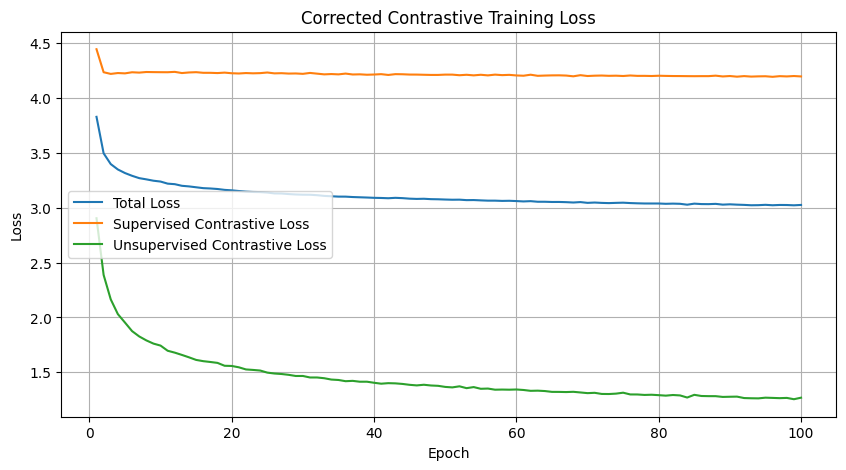

In [30]:
# ============================================================
# TRAINING LOSS CURVES
# ============================================================

import matplotlib.pyplot as plt


epochs_axis = np.arange(
    1,
    EPOCHS + 1
)


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    epochs_axis,
    history["total_loss"],
    label="Total Loss"
)

plt.plot(
    epochs_axis,
    history["supervised_loss"],
    label="Supervised Contrastive Loss"
)

plt.plot(
    epochs_axis,
    history["unsupervised_loss"],
    label="Unsupervised Contrastive Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Corrected Contrastive Training Loss"
)

plt.legend()

plt.grid(True)

plt.show()

In [31]:
# ============================================================
# GENERATE LEARNED EMBEDDINGS
# ============================================================

model.eval()


all_real_tensor = torch.from_numpy(
    X_real_all
)


embedding_batches = []


with torch.inference_mode():

    for start in range(
        0,
        len(all_real_tensor),
        BATCH_SIZE
    ):

        batch_real = (
            all_real_tensor[
                start:start + BATCH_SIZE
            ]
            .to(
                device,
                non_blocking=True
            )
        )


        z = model(
            batch_real
        )[1]


        embedding_batches.append(
            z.cpu().numpy()
        )


X_learned = np.concatenate(
    embedding_batches,
    axis=0
)
print(z.shape)

print(
    "Learned embedding shape:",
    X_learned.shape
)

torch.Size([500, 256])
Learned embedding shape: (14000, 256)


In [32]:
# ============================================================
# FINAL EMBEDDING VERIFICATION
# ============================================================



embedding_norms = np.linalg.norm(
    X_learned,
    axis=1
)


print(
    "Minimum embedding norm:",
    embedding_norms.min()
)

print(
    "Maximum embedding norm:",
    embedding_norms.max()
)

print(
    "Mean embedding norm:",
    embedding_norms.mean()
)



print("\n✓ Learned embeddings verified.")

Minimum embedding norm: 2.034053
Maximum embedding norm: 25.263992
Mean embedding norm: 7.367636

✓ Learned embeddings verified.


In [33]:
# ============================================================
# VERIFY MASTER GCD SPLIT FOR EVALUATION
#
# IMPORTANT:
# DO NOT CREATE A NEW RANDOM SPLIT HERE.
#
# Cell 7 already created:
#     known_indices
#     unknown_indices
#
# We reuse those exact indices.
# ============================================================

print("=" * 70)
print("VERIFYING MASTER GCD SPLIT")
print("=" * 70)



# ------------------------------------------------------------
# Verify no overlap
# ------------------------------------------------------------

assert len(
    np.intersect1d(
        known_indices,
        unknown_indices
    )
) == 0


# ------------------------------------------------------------
# Verify complete coverage
# ------------------------------------------------------------

assert len(
    np.union1d(
        known_indices,
        unknown_indices
    )
) == 14000


# ------------------------------------------------------------
# Create master integer labels
# ------------------------------------------------------------

label_to_int = {
    class_name: class_id
    for class_id, class_name
    in enumerate(CLASS_ORDER)
}

int_to_label = {
    class_id: class_name
    for class_name, class_id
    in label_to_int.items()
}


y_split = np.array(
    [
        label_to_int[str(label)]
        for label in df_real["label"]
    ],
    dtype=np.int64
)


assert y_split.shape == (
    14000,
)


# ------------------------------------------------------------
# Create boolean labeled mask
# ------------------------------------------------------------

known_mask_all = np.zeros(
    14000,
    dtype=bool
)

known_mask_all[
    known_indices
] = True




# ------------------------------------------------------------
# Verify every known class has 700 labels
# ------------------------------------------------------------

print("\nPer-class split:")

for class_id, class_name in enumerate(
    CLASS_ORDER
):

    class_mask = (
        y_split == class_id
    )

    labeled_count = np.sum(
        known_mask_all &
        class_mask
    )

    unlabeled_count = np.sum(
        (~known_mask_all) &
        class_mask
    )


    print(
        f"{class_name:20s} "
        f"Labeled={labeled_count:4d} "
        f"Unlabeled={unlabeled_count:4d}"
    )


    if class_name in KNOWN_CLASSES:

        assert labeled_count == 700
        assert unlabeled_count == 300

    else:

        assert labeled_count == 0
        assert unlabeled_count == 1000


print("\n✓ Master GCD split verified.")

VERIFYING MASTER GCD SPLIT

Per-class split:
Accordion            Labeled= 700 Unlabeled= 300
Acoustic_Guitar      Labeled= 700 Unlabeled= 300
Banjo                Labeled= 700 Unlabeled= 300
Electro_Guitar       Labeled= 700 Unlabeled= 300
flute                Labeled= 700 Unlabeled= 300
Harmonium            Labeled= 700 Unlabeled= 300
Trombone             Labeled= 700 Unlabeled= 300
Shakers              Labeled= 700 Unlabeled= 300
Keyboard             Labeled= 700 Unlabeled= 300
Bass_Guitar          Labeled=   0 Unlabeled=1000
Organ                Labeled=   0 Unlabeled=1000
Horn                 Labeled=   0 Unlabeled=1000
Mandolin             Labeled=   0 Unlabeled=1000
Drum_set             Labeled=   0 Unlabeled=1000

✓ Master GCD split verified.
